In [12]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


x = np.arange(1, 7, dtype=float)
p = x / np.sum(x)
distortion = (2.0 / 5.0) * (x[:, None] - x[None, :]) ** 2 #matrix source--recon
lambdas = np.geomspace(0.01, 30.0, 160) #increasing_ small rate -- accurate recon
tolerance = 1e-11
max_iterations = 100000


In [13]:
def conventional_rd(lam):
    """minimize I(X;Y) + lam * E[d(X,Y)]"""
    kernel = np.exp(-lam * distortion)
    q = np.ones(len(x)) / len(x)

    for iteration in range(max_iterations):
        transition = kernel * q[None, :]
        transition = transition / transition.sum(axis=1, keepdims=True)
        new_q = p @ transition

        error = np.max(np.abs(new_q - q))
        q = new_q
        if error < tolerance:
            return transition


def zepe_rd(lam):
    """Scale the joint distribution to P=Q"""
    joint = np.exp(-lam * distortion)

    for iteration in range(max_iterations):
        scale = np.sqrt(p / joint.sum(axis=1))
        joint = scale[:, None] * joint * scale[None, :]

        error = np.max(np.abs(joint.sum(axis=1) - p))
        if error < tolerance:
            return joint / p[:, None]


def measure(transition):
    """I(X;Y), KL(P || Q)."""
    joint = p[:, None] * transition
    q = joint.sum(axis=0)
    average_distortion = np.sum(joint * distortion)

    positive = joint > 0
    source_grid = np.broadcast_to(p[:, None], joint.shape)
    output_grid = np.broadcast_to(q[None, :], joint.shape)
    log_ratio = np.log(joint[positive]) - np.log(source_grid[positive]) - np.log(output_grid[positive])
    rate = np.sum(joint[positive] * log_ratio)

    kl = np.sum(p * (np.log(p) - np.log(q)))

    return average_distortion, max(0.0, rate), max(0.0, kl)



/tmp/ipykernel_1872/664142635.py:42: RuntimeWarning: divide by zero encountered in log
  kl = np.sum(p * (np.log(p) - np.log(q)))


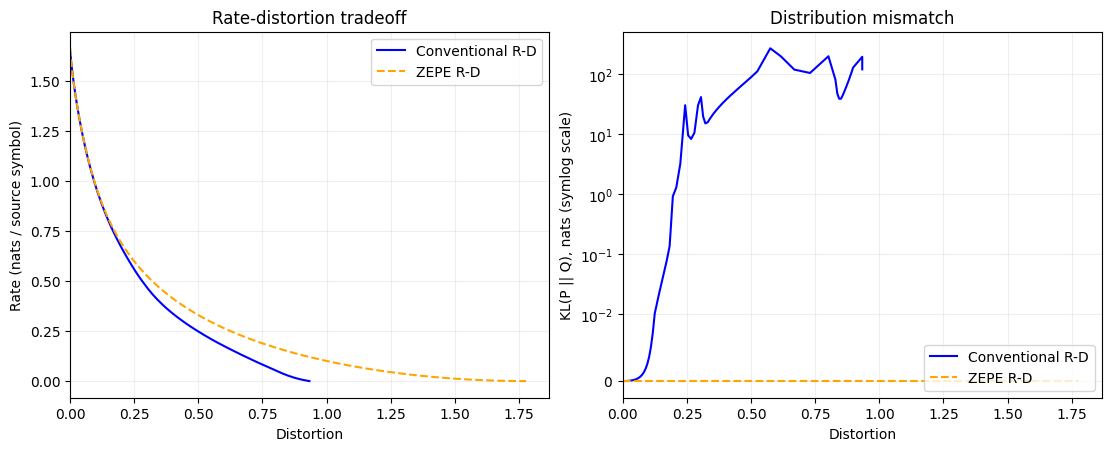

Source entropy : 1.6623769591928221
Conventional zero-rate distortion: 0.9333333333333333
ZEPE zero-rate distortion: 1.7777777777777777
Largest ZEPE KL : 2.114710523097075e-16


In [14]:

conventional = []
zepe = []

# Exact lossless endpoint: Y = X.
identity = np.eye(len(x))
conventional.append(measure(identity))
zepe.append(measure(identity))

for lam in lambdas:
    conventional.append(measure(conventional_rd(lam)))
    zepe.append(measure(zepe_rd(lam)))

# Exact zero-rate conventional endpoint: output a constant symbol.
best_symbol = np.argmin(p @ distortion)
constant_output = np.zeros((len(x), len(x)))
constant_output[:, best_symbol] = 1.0
conventional.append(measure(constant_output))

# Exact zero-rate ZEPE endpoint: draw Y independently from p.
independent_output = np.tile(p, (len(x), 1))
zepe.append(measure(independent_output))

conventional = np.array(conventional)
zepe = np.array(zepe)
conventional = conventional[np.argsort(conventional[:, 0])]
zepe = zepe[np.argsort(zepe[:, 0])]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
axes[0].plot(conventional[:, 0], conventional[:, 1], color="blue", label="Conventional R-D")
axes[0].plot(zepe[:, 0], zepe[:, 1], "--", color="orange", label="ZEPE R-D")
axes[0].set_ylabel("Rate (nats / source symbol)")
axes[0].set_title("Rate-distortion tradeoff")

finite = np.isfinite(conventional[:, 2])
axes[1].plot(conventional[finite, 0], conventional[finite, 2], color="blue", label="Conventional R-D")
axes[1].plot(zepe[:, 0], zepe[:, 2], "--", color="orange", label="ZEPE R-D")
axes[1].set_yscale("symlog", linthresh=0.01)
axes[1].set_ylabel("KL(P || Q), nats (symlog scale)")
axes[1].set_title("Distribution mismatch")

for ax in axes:
    ax.set_xlabel("Distortion")
    ax.set_xlim(left=0)
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")
axes[1].legend(loc="lower right")

# fig.savefig(output / "fig1.png", dpi=220, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Source entropy :", -np.sum(p * np.log(p)))
print("Conventional zero-rate distortion:", measure(constant_output)[0])
print("ZEPE zero-rate distortion:", measure(independent_output)[0])
print("Largest ZEPE KL :", np.max(zepe[:, 2]))